In [ ]:
import networkx as nx
import random
import matplotlib.pyplot as plt



In [ ]:
def get_random_nodes(graph):
    random_set_nodes = [x for x in g.nodes]
    random.shuffle(random_set_nodes)
    return random_set_nodes[:2]

def colourNode(status):
    if status == 'inactive':
        return "#808080" #inactive
    elif status == 'active':
        return 'red' #active
    elif status=='used':
        return 'blue' # for used nodes

def assign_seed_active(graph):
    for n in get_random_nodes(graph):
        graph.add_node(n, status='active')
        return graph

def turn(probability: float)->bool:
    if random.random() <= probability: # random no. is between 0 and 1 
        return True
    return False

# the nodes are tracked as 'active', 'inactive' and 'used'
def run_ind_cascade(s: nx.DiGraph, p_turning: float) -> nx.DiGraph:
    for node in get_active_nodes(s):
        s.add_node(node, status='used')
        for neighbour in s.adj[node]:
            if turn(p_turning) and s.nodes[neighbour]['status'] == 'inactive':
                s.add_node(neighbour, status='active')
    return s

def get_active_nodes(G: nx.DiGraph):
    nodes = []
    for n in G.nodes.data():
        if n[1]['status']=='active':
            nodes.append(n[0])
    return nodes

def colourGraph(g: nx.DiGraph):
    for node in g.nodes.data():
        g.add_node(node[0], status=node[1]['status'], colour=colourNode(node[1]['status'])) 


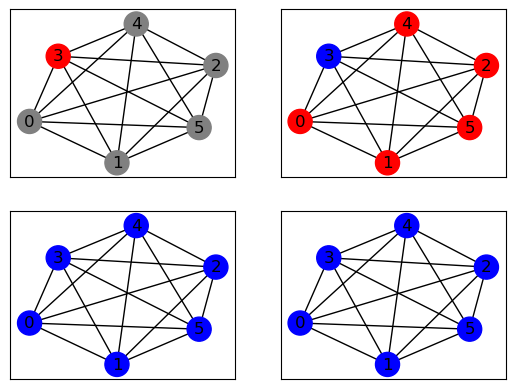

In [85]:
#g = assign_seed_active(create_test_graph())
g = nx.complete_graph(6)
for n in g.nodes.data():
    g.add_node(n[0], status='inactive')
assign_seed_active(g)

probability_turning = 1
p = nx.arf_layout(g)

plt.subplot(221)
colourGraph(g)
nx.draw_networkx(g, pos=p, node_color=[col[1]['colour'] for col in g.nodes.data()])

g = run_ind_cascade(g, probability_turning)
plt.subplot(222)
colourGraph(g)
nx.draw_networkx(g, pos=p,node_color=[col[1]['colour'] for col in g.nodes.data()])

g = run_ind_cascade(g, probability_turning)
plt.subplot(223)
colourGraph(g)
nx.draw_networkx(g, pos=p,node_color=[col[1]['colour'] for col in g.nodes.data()])

g = run_ind_cascade(g, probability_turning)
plt.subplot(224)
colourGraph(g)
nx.draw_networkx(g,pos=p, node_color=[col[1]['colour'] for col in g.nodes.data()])


In [ ]:
def all_nodes_complete(G: nx.DiGraph):
    for n in G.nodes.data():
        if n[1]['status'] == 'active':
            return False
    return True

def icc_runner(start_graph, start_nodes, p_turn = 0.5):
    if start_graph == None or start_nodes == None:
        print("Encountered An Erro")

    # give all nodes a status of 'inactive'        
    g: nx.DiGraph = start_graph

    for n in start_graph.nodes.data():
        g.add_node(n[0], status='inactive')
    
    # make the startnodes have an attribute 'active'
    for s in start_nodes:
        start_graph.add_node(s, status='active')

    i = 0
    while not all_nodes_complete(g):
        g=  run_ind_cascade(g, p_turn)
        i+=1
    return (i, g)

a = nx.complete_graph(6)
Result = icc_runner(nx.complete_graph(6), [3,2], 0.2)


In [104]:
def DCC(g:nx.DiGraph, seed, p:float = 0.5):
    for n in g.nodes.data():
        g.add_node(n[0], status='inactive', prob=p)
    for s in seed:
        g.add_node(s, status='active')
    i= 0
    while not all_nodes_complete(g):
        g = run_dcc(g)
        i+=1
    return g
    

def run_dcc(g):
    for node in get_active_nodes(g):
        g.add_node(node, status='used')
        for neighbour in g.adj[node]:
            if g.nodes[neighbour]['status'] == 'inactive':
                if turn(g.nodes[neighbour]['prob']):
                    g.add_node(neighbour, status='active')
                else:
                    g.add_node(neighbour, prob = g.nodes[neighbour]['prob'] * 0.8)
    return g
            
    
DCC(nx.graph_atlas(1000), [1,2])

SyntaxError: invalid syntax (3923463371.py, line 16)